In [1]:
import matplotlib as plt
import matplotlib.pyplot as pyplt
import numpy as np
import seaborn as sns
from scipy import stats

from slide_datatypes import difficulty_colours, SlidePattern, ChartDifficulty
from base_slide_dataset import full_df, pruned_df

In [2]:
len(pruned_df)

45151

In [3]:
master_df = pruned_df[pruned_df['difficulty'] == 5]
mas_outlier_removed_df = master_df[np.abs(stats.zscore(master_df['star_duration'])) < 3]
mas_straight_slide_df = mas_outlier_removed_df[mas_outlier_removed_df['pattern_group'] == SlidePattern.straight]
mas_across_straight_slide_df = mas_straight_slide_df[mas_straight_slide_df['cw_distance'] == 4]

remaster_df = pruned_df[pruned_df['difficulty'] == 6]
remas_outlier_removed_df = remaster_df[np.abs(stats.zscore(remaster_df['star_duration'])) < 3]
remas_straight_slide_df = remas_outlier_removed_df[remas_outlier_removed_df['pattern_group'] == SlidePattern.straight]
remas_across_straight_slide_df = remas_straight_slide_df[remas_straight_slide_df['cw_distance'] == 4]

mas_sdt_across_straight_slide_df = mas_across_straight_slide_df[mas_across_straight_slide_df['version'] == 'sdt']

len(mas_sdt_across_straight_slide_df)

510

In [4]:
mas_constant_ten_above_df = mas_across_straight_slide_df[mas_across_straight_slide_df["difficulty_constant"] >= 10]
mas_sdt_constant_ten_above_df = mas_sdt_across_straight_slide_df[mas_sdt_across_straight_slide_df["difficulty_constant"] >= 10]

remas_constant_ten_above_df = remas_across_straight_slide_df[remas_across_straight_slide_df["difficulty_constant"] >= 10]

<Axes: xlabel='duration_with_delay', ylabel='star_duration'>

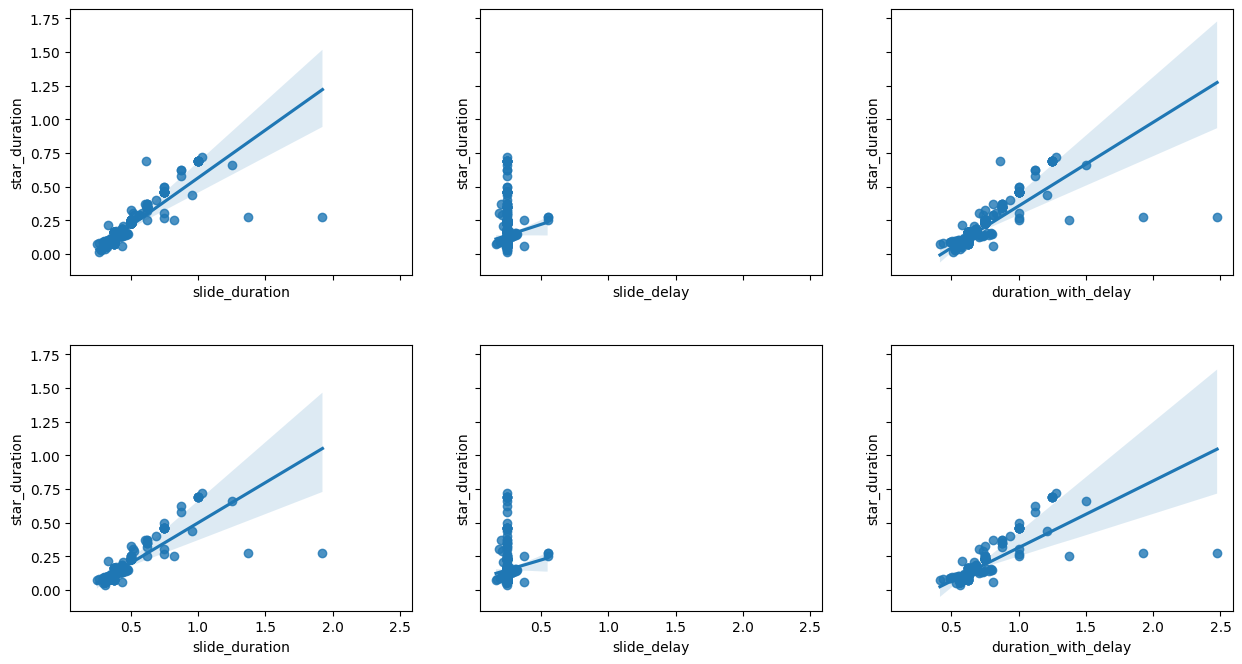

In [5]:
# star_duration_bpm_correlation_plot = sns.lmplot(data=outlier_removed_df, x="duration_with_delay", y="star_duration")
# star_duration_bpm_correlation_plot.figure.suptitle('Star duration vs BPM', x = 0.5, y = 1.1)
    # plot.text(10, 10, 'hello')

# plot.se(30, 30)

fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = pyplt.subplots(ncols=3, nrows=2, sharey=True, sharex=True, subplot_kw=dict(aspect='equal'), figsize=[15, 8])

sns.regplot(x=mas_across_straight_slide_df["slide_duration"], y=mas_across_straight_slide_df["star_duration"], ax=ax1)
sns.regplot(x=mas_across_straight_slide_df["slide_delay"], y=mas_across_straight_slide_df["star_duration"], ax=ax2)
sns.regplot(x=mas_across_straight_slide_df["duration_with_delay"], y=mas_across_straight_slide_df["star_duration"], ax=ax3)

sns.regplot(x=mas_sdt_across_straight_slide_df["slide_duration"], y=mas_sdt_across_straight_slide_df["star_duration"], ax=ax4)
sns.regplot(x=mas_sdt_across_straight_slide_df["slide_delay"], y=mas_sdt_across_straight_slide_df["star_duration"], ax=ax5)
sns.regplot(x=mas_sdt_across_straight_slide_df["duration_with_delay"], y=mas_sdt_across_straight_slide_df["star_duration"], ax=ax6)

# star_duration_bpm_correlation_plot.savefig(f"straight_slide_across_screen_outlier_chart.png")

<Axes: xlabel='duration_with_delay', ylabel='star_duration'>

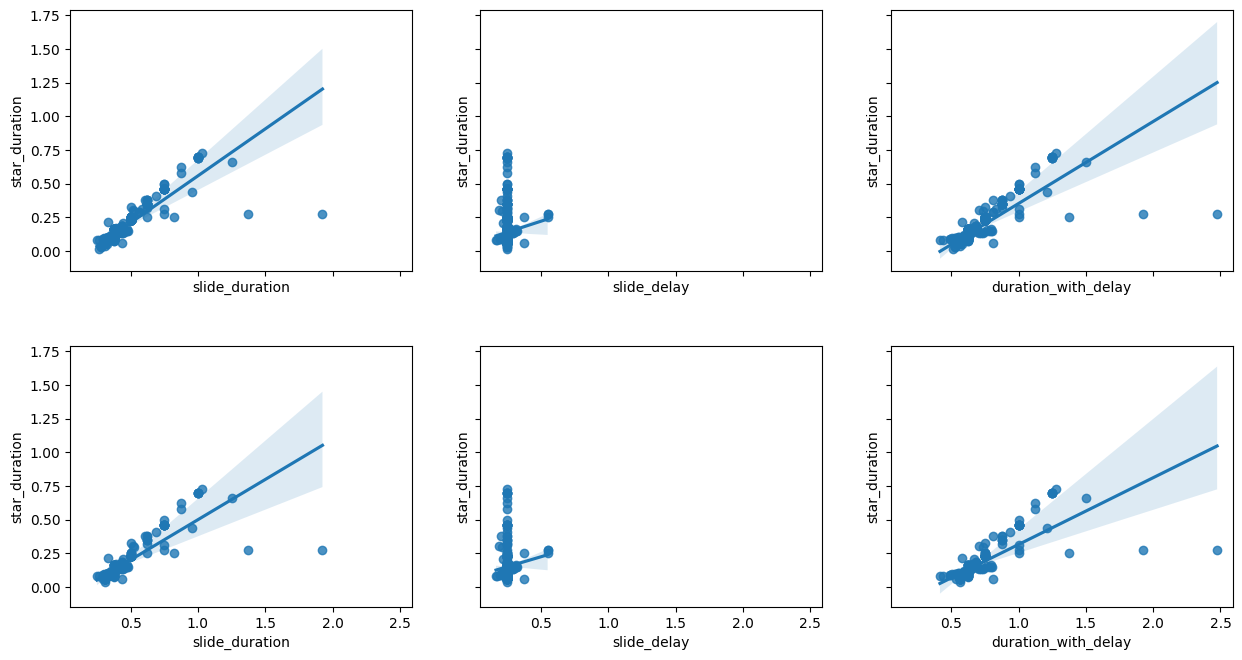

In [6]:
fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = pyplt.subplots(ncols=3, nrows=2, sharey=True, sharex=True, subplot_kw=dict(aspect='equal'), figsize=[15, 8])

sns.regplot(x=mas_constant_ten_above_df["slide_duration"], y=mas_constant_ten_above_df["star_duration"], ax=ax1)


sns.regplot(x=mas_constant_ten_above_df["slide_delay"], y=mas_constant_ten_above_df["star_duration"], ax=ax2)
sns.regplot(x=mas_constant_ten_above_df["duration_with_delay"], y=mas_constant_ten_above_df["star_duration"], ax=ax3)

sns.regplot(x=mas_sdt_constant_ten_above_df["slide_duration"], y=mas_sdt_constant_ten_above_df["star_duration"], ax=ax4)
sns.regplot(x=mas_sdt_constant_ten_above_df["slide_delay"], y=mas_sdt_constant_ten_above_df["star_duration"], ax=ax5)
sns.regplot(x=mas_sdt_constant_ten_above_df["duration_with_delay"], y=mas_sdt_constant_ten_above_df["star_duration"], ax=ax6)

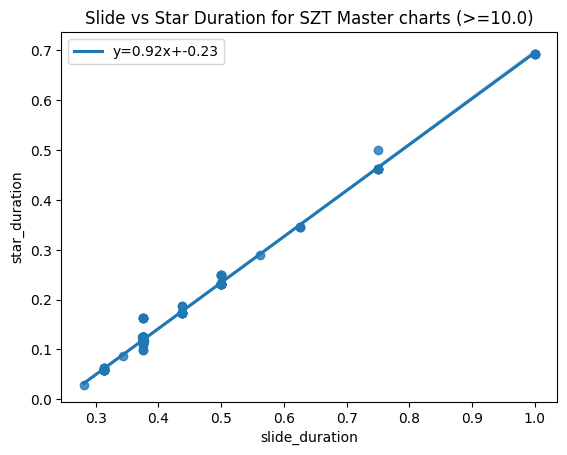

In [7]:
szt_constant_ten_above_df = mas_constant_ten_above_df[mas_constant_ten_above_df['version'] == 'szt']

# get coeffs of linear fit
result = stats.linregress(szt_constant_ten_above_df["slide_duration"], szt_constant_ten_above_df["star_duration"])


# use line_kws to set line label for legend
ax = sns.regplot(x="slide_duration", y="star_duration", data=szt_constant_ten_above_df, 
 line_kws={'label':"y={0:.2f}x+{1:.2f}".format(result.slope,result.intercept)})

ax.set_title("Slide vs Star Duration for SZT Master charts (>=10.0)")

# plot legend
ax.legend()

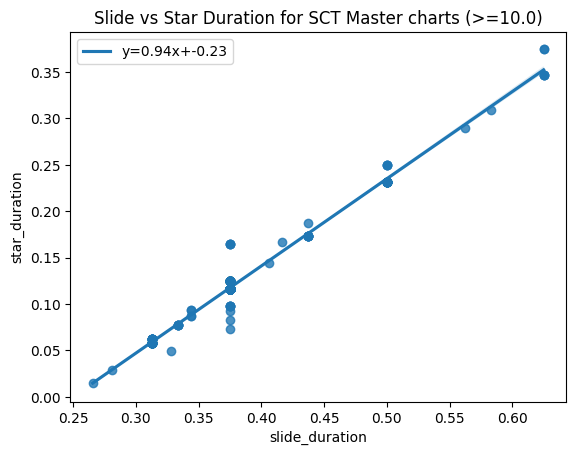

In [8]:
mas_sct_constant_ten_above_df = mas_constant_ten_above_df[mas_constant_ten_above_df['version'] == 'sct']

# get coeffs of linear fit
result = stats.linregress(mas_sct_constant_ten_above_df["slide_duration"], mas_sct_constant_ten_above_df["star_duration"])


# use line_kws to set line label for legend
ax = sns.regplot(x="slide_duration", y="star_duration", data=mas_sct_constant_ten_above_df, 
 line_kws={'label':"y={0:.2f}x+{1:.2f}".format(result.slope,result.intercept)})

ax.set_title("Slide vs Star Duration for SCT Master charts (>=10.0)")

# plot legend
ax.legend()

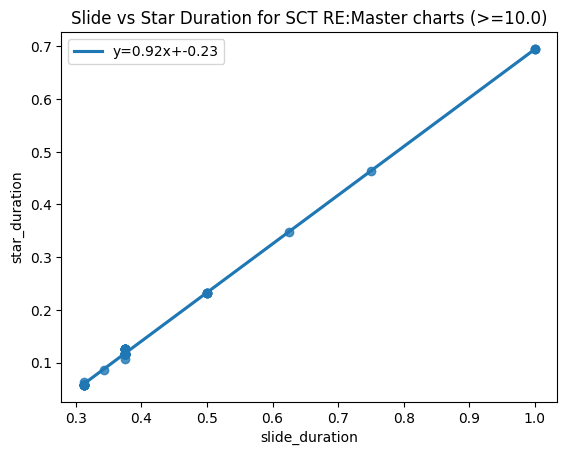

In [9]:
remas_sct_constant_ten_above_df = remas_constant_ten_above_df[remas_constant_ten_above_df['version'] == 'sct']

# get coeffs of linear fit
result = stats.linregress(remas_sct_constant_ten_above_df["slide_duration"], remas_sct_constant_ten_above_df["star_duration"])


# use line_kws to set line label for legend
ax = sns.regplot(x="slide_duration", y="star_duration", data=remas_sct_constant_ten_above_df, 
 line_kws={'label':"y={0:.2f}x+{1:.2f}".format(result.slope,result.intercept)})

ax.set_title("Slide vs Star Duration for SCT RE:Master charts (>=10.0)")

# plot legend
ax.legend()

In [10]:
remas_constant_ten_above_df = mas_constant_ten_above_df[mas_constant_ten_above_df['version'] == 'sct']

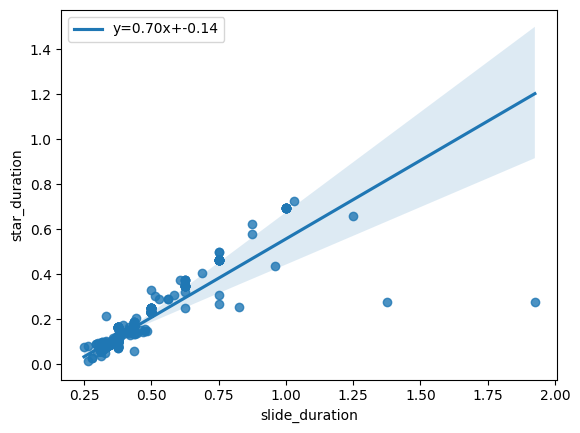

In [ ]:
# get coeffs of linear fit
result = stats.linregress(mas_constant_ten_above_df["slide_duration"], mas_constant_ten_above_df["star_duration"])


# use line_kws to set line label for legend
ax = sns.regplot(x="slide_duration", y="star_duration", data=mas_constant_ten_above_df, 
 line_kws={'label':"y={0:.2f}x+{1:.2f}".format(result.slope,result.intercept)})

# plot legend
ax.legend()

Text(0.5, 1.0, 'Slide vs Star Duration across all Master Chart straight slides (>=10.0)')

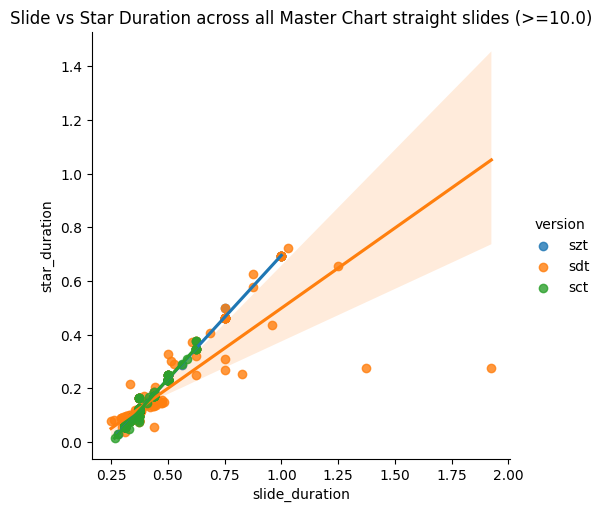

In [16]:
star_duration_bpm_correlation_plot = sns.lmplot(data=mas_constant_ten_above_df, x="slide_duration", y="star_duration", hue="version")
ax = pyplt.gca()
ax.set_title("Slide vs Star Duration across all Master Chart straight slides (>=10.0)")